# Playing Atari with Deep Reinforcement Learning (DQN)

**Paper:** Mnih et al. (2013), *Playing Atari with Deep Reinforcement Learning*, arXiv:1312.5602

This notebook builds a Deep Q-Network (DQN) from scratch. It has the core parts of the paper: **experience replay** (a replay buffer we sample random minibatches from) and **ε-greedy exploration** (a random action with probability ε, which shrinks over time). It also adds a **target network** (a frozen copy of the network, updated now and then, that gives stable targets). The target network comes from the team's 2015 Nature follow-up, not from the 2013 paper.

We train on CartPole-v1 (a small classic control task) with an MLP Q-network. This keeps the DQN algorithm the same while staying CPU-friendly.

## 1. Setup & Imports

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import random

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cpu


## 2. Install Environment Library

We use `gymnasium` (the maintained successor to OpenAI Gym) for the CartPole environment.

In [2]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'gymnasium'])
import gymnasium as gym
print(f'Gymnasium version: {gym.__version__}')

Gymnasium version: 1.4.0



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: /private/tmp/claude-501/-Users-nadeem-projects-research-papers/8671a4b1-1c7e-4110-8c22-be367e02293f/scratchpad/venv/bin/python3.14 -m pip install --upgrade pip


## 3. Hyperparameters

Key settings for CartPole-v1. The 2013 Atari paper used a much bigger replay memory (1M frames). The periodic target update (every 10,000 steps) and the Huber-style loss come from the 2015 Nature version. Here we use a 10,000-transition buffer and copy the target network every 250 steps.

In [3]:
# Environment
ENV_NAME = 'CartPole-v1'

# Network
state_dim = 4          # CartPole: [cart_pos, cart_vel, pole_angle, pole_ang_vel]
action_dim = 2         # CartPole: [push_left, push_right]
hidden_dim = 128       # Hidden layer size

# Training
lr = 2.5e-4            # Learning rate
gamma = 0.99           # Discount factor
batch_size = 64        # Minibatch size
buffer_size = 10000    # Replay buffer capacity (paper used 1M for Atari)
target_update_freq = 250  # Steps between target network updates (paper used 10000)
num_episodes = 600     # Training episodes
max_steps = 500        # Max steps per episode (CartPole-v1 cap)
min_buffer_size = 500  # Min transitions before training starts
grad_clip = 10.0       # Gradient norm clipping

# Exploration (epsilon-greedy)
epsilon_start = 1.0    # Initial exploration rate
epsilon_end = 0.01     # Minimum exploration rate
epsilon_decay = 0.995  # Per-episode decay rate

print(f'Environment: {ENV_NAME}')
print(f'State dim: {state_dim}, Action dim: {action_dim}')
print(f'Episodes: {num_episodes}, Max steps: {max_steps}')
print(f'Buffer: {buffer_size}, Batch: {batch_size}, Min buffer: {min_buffer_size}')
print(f'Target update every: {target_update_freq} steps')
print(f'LR: {lr}, Gamma: {gamma}, Grad clip: {grad_clip}')

Environment: CartPole-v1
State dim: 4, Action dim: 2
Episodes: 600, Max steps: 500
Buffer: 10000, Batch: 64, Min buffer: 500
Target update every: 250 steps
LR: 0.00025, Gamma: 0.99, Grad clip: 10.0


## 4. Environment Setup

CartPole-v1: a pole is attached to a cart that moves along a frictionless track. The goal is to keep the pole upright for as long as possible. The episode ends when the pole tilts more than ±12° or the cart moves more than 2.4 units from the center.

- **Observation:** cart position, cart velocity, pole angle, pole angular velocity
- **Actions:** push the cart left or right
- **Reward:** +1 for every step the pole stays up
- **Max episode length:** 500 steps

In [4]:
env = gym.make(ENV_NAME)
print(f'Observation space: {env.observation_space}')
print(f'Action space: {env.action_space}')

# Test a random episode
state, _ = env.reset(seed=42)
total_reward = 0
for _ in range(100):
    action = env.action_space.sample()
    state, reward, terminated, truncated, _ = env.step(action)
    total_reward += reward
    if terminated or truncated:
        break
print(f'Random agent reward (100 steps max): {total_reward}')
env.close()

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Random agent reward (100 steps max): 23.0


## 5. Q-Network

The Q-network estimates Q(s, a) for all actions at once. It takes a state as input and outputs one Q-value per action. The greedy action is the `argmax` over the output.

The 2013 paper used a small CNN for pixel inputs: 2 conv layers + 1 fully connected hidden layer (256 units), then a linear output layer. (The 3 conv + 2 FC network is the 2015 Nature version.) We use an MLP for the 4-number CartPole state. The Q-learning algorithm is the same; only the input type changes.

In [5]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim):
        super(QNetwork, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, x):
        return self.net(x)

# Create policy network and target network
policy_net = QNetwork(state_dim, action_dim, hidden_dim).to(device)
target_net = QNetwork(state_dim, action_dim, hidden_dim).to(device)
target_net.load_state_dict(policy_net.state_dict())  # Initialize target = policy
target_net.eval()  # Target net is not trained by gradients

print('Policy Network:')
print(policy_net)
print(f'Parameters: {sum(p.numel() for p in policy_net.parameters()):,}')

Policy Network:
QNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
Parameters: 17,410


## 6. Experience Replay Buffer

This buffer stores transitions (s, a, r, s', done) and returns random minibatches. It is a core idea of the paper: random sampling breaks the link between back-to-back samples and makes training more stable.

The paper used a replay memory of 1,000,000 frames. We use 10,000 transitions, which is enough for CartPole.

In [6]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            torch.FloatTensor(np.array(states)).to(device),
            torch.LongTensor(actions).to(device),
            torch.FloatTensor(rewards).to(device),
            torch.FloatTensor(np.array(next_states)).to(device),
            torch.FloatTensor(dones).to(device)
        )

    def __len__(self):
        return len(self.buffer)

replay_buffer = ReplayBuffer(buffer_size)
print(f'Replay buffer created with capacity {buffer_size}')

Replay buffer created with capacity 10000


## 7. ε-Greedy Action Selection

With probability ε, pick a random action (exploration). Otherwise, pick the action with the highest Q-value (exploitation).

ε starts at 1.0 and is multiplied by 0.995 after each episode, with a floor of 0.01. After 600 episodes it only reaches about 0.049, so the floor is never hit in this run.

In [7]:
def select_action(state, policy_net, epsilon, action_dim):
    """Epsilon-greedy action selection."""
    if random.random() < epsilon:
        return random.randrange(action_dim)
    with torch.no_grad():
        state_t = torch.FloatTensor(state).unsqueeze(0).to(device)
        q_values = policy_net(state_t)
        return q_values.argmax(dim=1).item()

# Test action selection
test_state = np.array([0.0, 0.0, 0.0, 0.0])
action = select_action(test_state, policy_net, 1.0, action_dim)  # Should be random
print(f'Action with ε=1.0 (random): {action}')
action = select_action(test_state, policy_net, 0.0, action_dim)  # Should be greedy
print(f'Action with ε=0.0 (greedy): {action}')

Action with ε=1.0 (random): 0
Action with ε=0.0 (greedy): 0


## 8. Q-Learning Optimization Step

The DQN loss: `L(θ) = E[Huber(y - Q(s, a; θ))]` where `y = r + γ max_a' Q(s', a'; θ⁻)`.

Key details:

- The target uses the **target network** (θ⁻), not the policy network (θ)
- The future reward term is set to zero only when the pole really falls or the cart leaves the track (`terminated`). Reaching the 500-step time limit is not a failure, so those transitions still look ahead
- **Huber loss** (SmoothL1) is used instead of plain squared error. It is more robust to outliers and helps stop Q-values from blowing up. The 2015 Nature paper clips the error in a similar way; the 2013 paper used plain squared error.
- **Gradient norm clipping** at 10.0 prevents exploding gradients

In [8]:
def optimize_model(policy_net, target_net, replay_buffer, optimizer, batch_size, gamma, grad_clip):
    """One step of DQN optimization."""
    if len(replay_buffer) < batch_size:
        return None

    states, actions, rewards, next_states, dones = replay_buffer.sample(batch_size)

    # Current Q-values for the actions that were taken
    current_q = policy_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)

    # Target Q-values using the target network
    with torch.no_grad():
        max_next_q = target_net(next_states).max(dim=1)[0]
        target_q = rewards + gamma * max_next_q * (1 - dones)

    # Huber loss (SmoothL1) — more robust than MSE, used in Nature DQN
    loss = F.smooth_l1_loss(current_q, target_q)

    optimizer.zero_grad()
    loss.backward()
    # Gradient norm clipping for stability
    torch.nn.utils.clip_grad_norm_(policy_net.parameters(), grad_clip)
    optimizer.step()

    return loss.item()

optimizer = optim.Adam(policy_net.parameters(), lr=lr)
print('Optimizer: Adam')
print(f'Learning rate: {lr}, Gamma: {gamma}, Grad clip: {grad_clip}')
print('Loss: Huber (SmoothL1)')

Optimizer: Adam
Learning rate: 0.00025, Gamma: 0.99, Grad clip: 10.0
Loss: Huber (SmoothL1)


## 9. Training Loop

This follows Algorithm 1 of the paper, plus the target-network steps from the 2015 Nature version:

1. Initialize the replay buffer, the policy network θ, and the target network θ⁻ = θ
2. For each episode:
   - Observe the initial state s
   - For each step:
     - Select action a via ε-greedy
     - Execute a, observe r and s'
     - Store (s, a, r, s', done) in the replay buffer
     - If the buffer is large enough: sample a minibatch, compute the loss, update θ
     - Every C steps: θ⁻ = θ
   - Decay ε

We track episode rewards, losses, and ε values for the plots.

In [9]:
env = gym.make(ENV_NAME)
epsilon = epsilon_start

episode_rewards = []
episode_losses = []
epsilon_history = []
step_count = 0

print('Starting DQN training...')
print(f'Episodes: {num_episodes}')
print('-' * 70)

for episode in range(num_episodes):
    state, _ = env.reset(seed=episode)
    episode_reward = 0
    episode_loss = []

    for step in range(max_steps):
        # Select action
        action = select_action(state, policy_net, epsilon, action_dim)

        # Execute action
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Store transition in replay buffer.
        # Only a real failure (terminated) cuts off the future reward. Hitting the 500-step
        # time limit (truncated) is not a failure, so the target still looks ahead.
        replay_buffer.push(state, action, reward, next_state, float(terminated))

        # Move to next state
        state = next_state
        episode_reward += reward
        step_count += 1

        # Optimize model (only after buffer has enough samples)
        loss = None
        if len(replay_buffer) >= min_buffer_size:
            loss = optimize_model(policy_net, target_net, replay_buffer, optimizer,
                                  batch_size, gamma, grad_clip)
        if loss is not None:
            episode_loss.append(loss)

        # Update target network periodically
        if step_count % target_update_freq == 0:
            target_net.load_state_dict(policy_net.state_dict())

        if done:
            break

    # Decay epsilon
    epsilon = max(epsilon_end, epsilon * epsilon_decay)

    # Record metrics
    episode_rewards.append(episode_reward)
    epsilon_history.append(epsilon)
    avg_loss = np.mean(episode_loss) if episode_loss else 0.0
    episode_losses.append(avg_loss)

    # Print progress
    if (episode + 1) % 50 == 0 or episode == 0:
        recent_avg = np.mean(episode_rewards[-50:])
        print(f'Ep {episode+1:4d} | R: {episode_reward:6.1f} | Avg(50): {recent_avg:6.1f} | ε: {epsilon:.3f} | Loss: {avg_loss:.4f} | Buf: {len(replay_buffer)}')

print('-' * 70)
print('Training complete!')
print(f'Final average reward (last 50): {np.mean(episode_rewards[-50:]):.1f}')
env.close()

Starting DQN training...
Episodes: 600
----------------------------------------------------------------------
Ep    1 | R:   14.0 | Avg(50):   14.0 | ε: 0.995 | Loss: 0.0000 | Buf: 14


Ep   50 | R:   11.0 | Avg(50):   18.4 | ε: 0.778 | Loss: 0.0234 | Buf: 920


Ep  100 | R:   14.0 | Avg(50):   41.1 | ε: 0.606 | Loss: 0.2094 | Buf: 2977


Ep  150 | R:  163.0 | Avg(50):   71.1 | ε: 0.471 | Loss: 0.3363 | Buf: 6530


Ep  200 | R:   18.0 | Avg(50):  100.2 | ε: 0.367 | Loss: 0.5562 | Buf: 10000


...

Ep  400 | R:   20.0 | Avg(50):   95.3 | ε: 0.135 | Loss: 0.2019 | Buf: 10000


Ep  450 | R:   79.0 | Avg(50):   99.9 | ε: 0.105 | Loss: 0.2479 | Buf: 10000


Ep  500 | R:  158.0 | Avg(50):  128.1 | ε: 0.082 | Loss: 0.2198 | Buf: 10000


Ep  550 | R:  129.0 | Avg(50):  191.6 | ε: 0.063 | Loss: 0.0720 | Buf: 10000


Ep  600 | R:  188.0 | Avg(50):  164.6 | ε: 0.049 | Loss: 0.4419 | Buf: 10000
----------------------------------------------------------------------
Training complete!
Final average reward (last 50): 164.6


## 10. Reward Curve

Plot the episode reward over training. A DQN agent that learns should show an upward trend toward the CartPole-v1 max reward of 500. We show both the raw rewards and a smoothed (moving average) curve.

In this run (seed 42) the learning is slow and noisy: the 50-episode average sits around 100 for most of training and only climbs to about 165–190 near the end. Section 15 trains the same agent with four more seeds to show how much DQN varies from run to run.

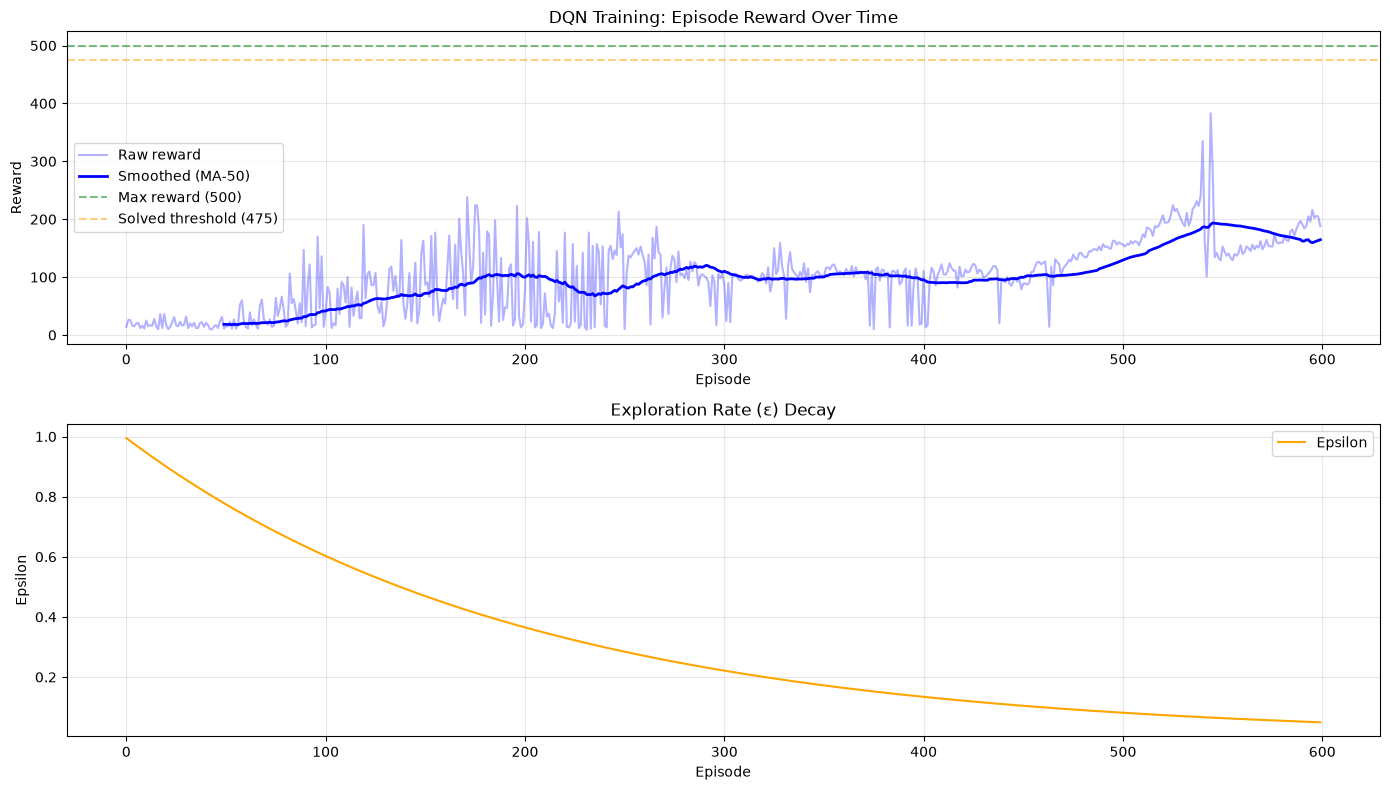

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

# Reward curve
ax1.plot(episode_rewards, alpha=0.3, color='blue', label='Raw reward')
window = 50
if len(episode_rewards) >= window:
    smoothed = np.convolve(episode_rewards, np.ones(window)/window, mode='valid')
    ax1.plot(range(window-1, len(episode_rewards)), smoothed, color='blue', linewidth=2, label=f'Smoothed (MA-{window})')
ax1.axhline(y=500, color='green', linestyle='--', alpha=0.5, label='Max reward (500)')
ax1.axhline(y=475, color='orange', linestyle='--', alpha=0.5, label='Solved threshold (475)')
ax1.set_xlabel('Episode')
ax1.set_ylabel('Reward')
ax1.set_title('DQN Training: Episode Reward Over Time')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Epsilon decay
ax2.plot(epsilon_history, color='orange', label='Epsilon')
ax2.set_xlabel('Episode')
ax2.set_ylabel('Epsilon')
ax2.set_title('Exploration Rate (ε) Decay')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Loss Curve

The Huber loss should mostly go down as the Q-values settle. Spikes can appear when the target network is updated, because the targets shift.

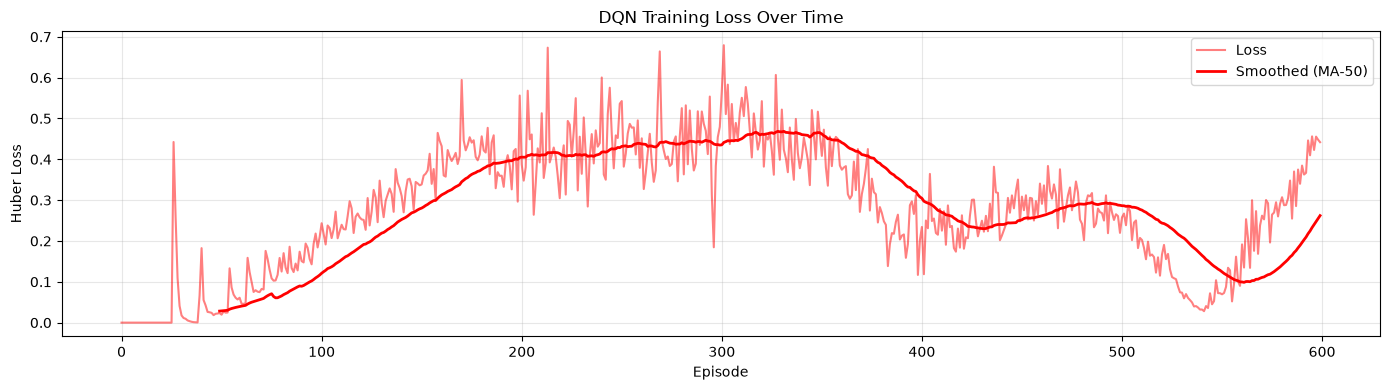

In [11]:
plt.figure(figsize=(14, 4))
plt.plot(episode_losses, alpha=0.5, color='red', label='Loss')
if len(episode_losses) >= window:
    smoothed_loss = np.convolve(episode_losses, np.ones(window)/window, mode='valid')
    plt.plot(range(window-1, len(episode_losses)), smoothed_loss, color='red', linewidth=2, label=f'Smoothed (MA-{window})')
plt.xlabel('Episode')
plt.ylabel('Huber Loss')
plt.title('DQN Training Loss Over Time')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Evaluation: Greedy Policy

Run the trained agent with ε=0 (pure greedy, no exploration) for 10 episodes and report the average reward. This measures the policy the agent actually learned.

In [12]:
def evaluate_policy(net, n_episodes=20, seed0=1000):
    """Run the greedy policy (ε=0) for n_episodes and return the episode rewards."""
    env = gym.make(ENV_NAME)
    rewards = []
    for episode in range(n_episodes):
        state, _ = env.reset(seed=seed0 + episode)
        total_reward = 0
        with torch.no_grad():
            for step in range(max_steps):
                state_t = torch.FloatTensor(state).unsqueeze(0).to(device)
                action = net(state_t).argmax(dim=1).item()
                state, reward, terminated, truncated, _ = env.step(action)
                total_reward += reward
                if terminated or truncated:
                    break
        rewards.append(total_reward)
    env.close()
    return rewards

rewards = evaluate_policy(policy_net)
print('Evaluation of the final weights (ε=0, 20 episodes):')
print(f'  Per-episode rewards: {[int(x) for x in rewards]}')
print(f'  Average reward: {np.mean(rewards):.1f} ± {np.std(rewards):.1f}   (min {min(rewards):.0f}, max {max(rewards):.0f})')
print(f'  Episodes that reached the 500 cap: {sum(x >= 500 for x in rewards)}/20')
print(f'  CartPole-v1 solved at: 475.0')
if np.mean(rewards) >= 475:
    print('  ✅ SOLVED! Average reward ≥ 475')
else:
    print(f'  Progress: {np.mean(rewards)/475*100:.1f}% of solving threshold')
    print('  Partly learned: well above a random agent, but the task is not solved yet.')

Evaluation of the final weights (ε=0, 20 episodes):
  Per-episode rewards: [194, 200, 202, 194, 190, 196, 193, 197, 195, 186, 205, 188, 195, 203, 206, 196, 190, 216, 207, 194]
  Average reward: 197.3 ± 7.2   (min 186, max 216)
  Episodes that reached the 500 cap: 0/20
  CartPole-v1 solved at: 475.0
  Progress: 41.5% of solving threshold
  Partly learned: well above a random agent, but the task is not solved yet.


## 13. Predicted Value vs. Actual Return

A Q-value is a prediction: "if I take this action now and play well afterwards, how much (discounted) reward will I collect?" We can check that prediction against what really happens.

We run one episode with the trained agent and plot, at every step, the value it predicts (`max Q(s, a)`) next to the discounted return it actually collected from that step to the end. With γ = 0.99 and +1 reward per step, an agent that expects to survive forever should predict `1 / (1 - γ) = 100`.

Near the end of an episode the actual return must fall toward 0, because there are only a few steps left to collect reward. So the gap at the far right is partly just "the episode ended". The interesting part is that the prediction stays near 100 the whole way: the agent does not see the failure coming.

The lower plot shows `|Q(push_left) - Q(push_right)|`, how much the agent's two options differ. Small values mean it is nearly indifferent between pushing left and right at that moment.

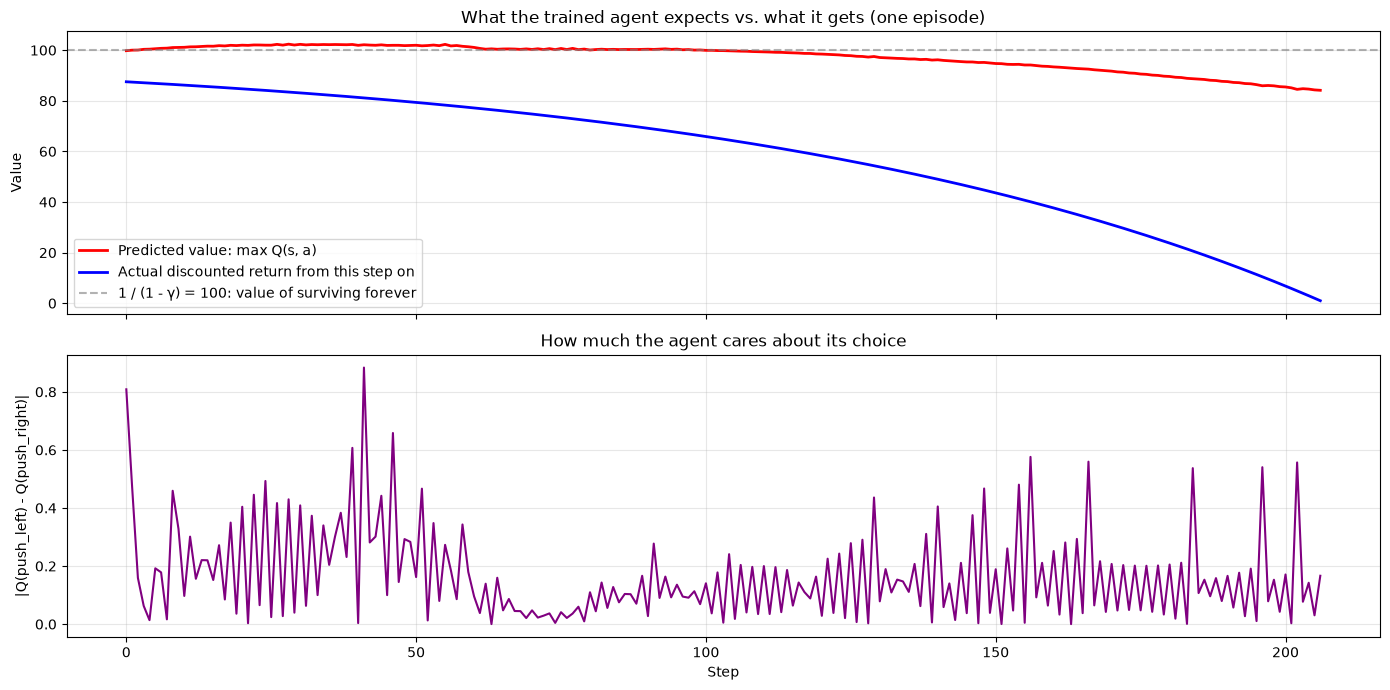

Episode length: 207 steps
Predicted value at step 0: 99.8   actual discounted return from step 0: 87.5
Average gap between the two actions: 0.168


In [13]:
# Run one episode with the best weights and record what the network predicts at every step
env = gym.make(ENV_NAME)
state, _ = env.reset(seed=7)
pred_q, q_gap, step_rewards = [], [], []

with torch.no_grad():
    for step in range(max_steps):
        q = policy_net(torch.FloatTensor(state).unsqueeze(0).to(device))[0].cpu().numpy()
        pred_q.append(q.max())
        q_gap.append(abs(q[0] - q[1]))
        state, reward, terminated, truncated, _ = env.step(int(q.argmax()))
        step_rewards.append(reward)
        if terminated or truncated:
            break
env.close()

# What the agent actually collected from each step onward (discounted)
actual_return = np.zeros(len(step_rewards))
running = 0.0
for t in reversed(range(len(step_rewards))):
    running = step_rewards[t] + gamma * running
    actual_return[t] = running

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ax1.plot(pred_q, color='red', linewidth=2, label='Predicted value: max Q(s, a)')
ax1.plot(actual_return, color='blue', linewidth=2, label='Actual discounted return from this step on')
ax1.axhline(y=1 / (1 - gamma), color='gray', linestyle='--', alpha=0.6, label='1 / (1 - γ) = 100: value of surviving forever')
ax1.set_ylabel('Value')
ax1.set_title('What the trained agent expects vs. what it gets (one episode)')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(q_gap, color='purple')
ax2.set_xlabel('Step')
ax2.set_ylabel('|Q(push_left) - Q(push_right)|')
ax2.set_title('How much the agent cares about its choice')
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Episode length: {len(step_rewards)} steps')
print(f'Predicted value at step 0: {pred_q[0]:.1f}   actual discounted return from step 0: {actual_return[0]:.1f}')
print(f'Average gap between the two actions: {np.mean(q_gap):.3f}')

## 14. Trained Agent Demonstration

Run one episode with the trained agent and plot the cart position and pole angle over time to see how it balances the pole.

In the saved run the pole stays well within the ±12° limit, but the cart slowly drifts to the edge of the track (±2.4) and the episode ends there. The agent has learned to keep the pole up, but not to keep the cart centered.

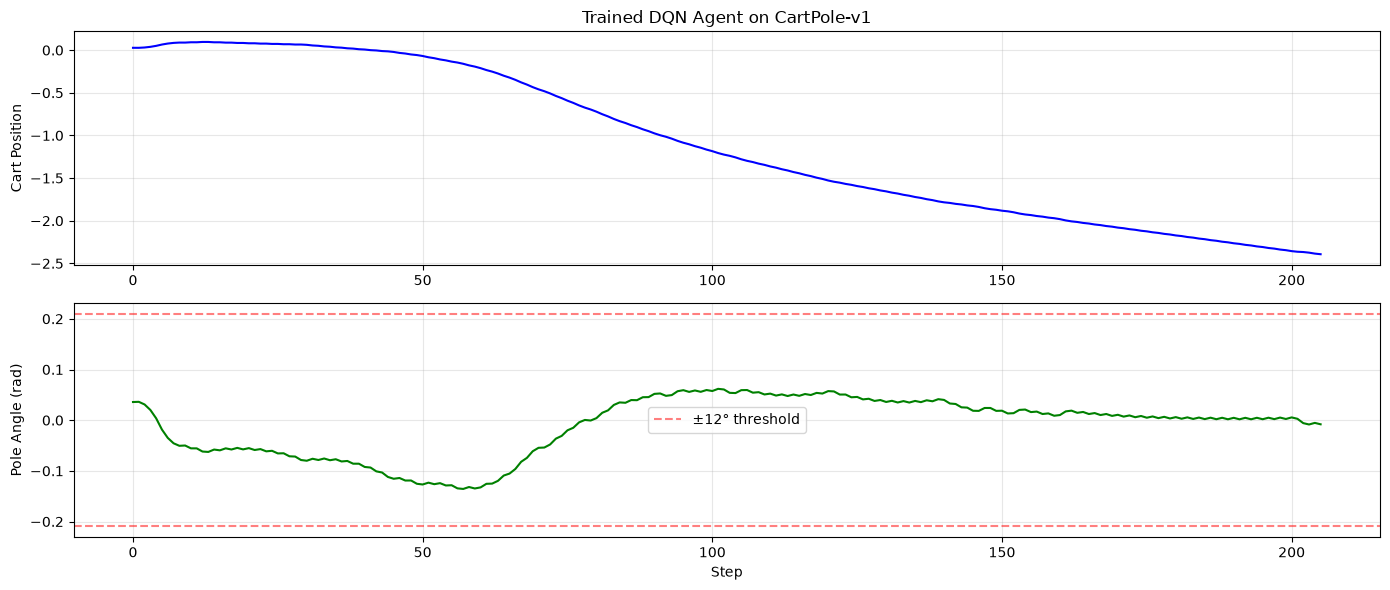

Total reward: 206
Final cart position: -2.392
Max pole angle: 0.1356 rad (7.8°)


In [14]:
env = gym.make(ENV_NAME)
state, _ = env.reset(seed=42)
positions = []
angles = []
rewards = []

with torch.no_grad():
    for step in range(max_steps):
        state_t = torch.FloatTensor(state).unsqueeze(0).to(device)
        q_values = policy_net(state_t)
        action = q_values.argmax(dim=1).item()

        positions.append(state[0])
        angles.append(state[2])
        rewards.append(1)

        state, reward, terminated, truncated, _ = env.step(action)
        if terminated or truncated:
            break

env.close()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6))
ax1.plot(positions, color='blue')
ax1.set_ylabel('Cart Position')
ax1.set_title('Trained DQN Agent on CartPole-v1')
ax1.grid(True, alpha=0.3)

ax2.plot(angles, color='green')
ax2.axhline(y=0.2094, color='red', linestyle='--', alpha=0.5, label='±12° threshold')
ax2.axhline(y=-0.2094, color='red', linestyle='--', alpha=0.5)
ax2.set_ylabel('Pole Angle (rad)')
ax2.set_xlabel('Step')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print(f'Total reward: {len(rewards)}')
print(f'Final cart position: {positions[-1]:.3f}')
print(f'Max pole angle: {max(abs(a) for a in angles):.4f} rad ({max(abs(a) for a in angles)*180/np.pi:.1f}°)')

## 15. Ablation: What Do the Target Network and Replay Actually Buy?

The paper's pitch is that DQN needs its tricks to be stable. Let's test that on CartPole. We train the same agent five times (seeds 0 to 4) in three versions and compare the learning curves:

- **Full DQN:** the setup used above.
- **No target network:** the "target" copy is refreshed at every step, so it is just the live network. The target moves every time the network does.
- **Tiny buffer (no real replay):** the buffer keeps only the last 64 transitions, so each minibatch is the most recent, strongly correlated experience instead of a random sample from the past.

Each run uses the same 600 episodes. Score = average reward over the last 50 episodes.

Small experiment, honest limits: 5 seeds per version and one easy task. Treat the pattern as a hint, not a proof.

In [15]:
def run_dqn(seed, buffer_cap=buffer_size, min_buffer=min_buffer_size, target_update=target_update_freq):
    """Train a fresh DQN with the same recipe as above and return the 600 episode rewards."""
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    policy = QNetwork(state_dim, action_dim, hidden_dim).to(device)
    target = QNetwork(state_dim, action_dim, hidden_dim).to(device)
    target.load_state_dict(policy.state_dict())
    opt = optim.Adam(policy.parameters(), lr=lr)
    buffer = ReplayBuffer(buffer_cap)
    env = gym.make(ENV_NAME)
    eps, steps, rewards = epsilon_start, 0, []
    for episode in range(num_episodes):
        state, _ = env.reset(seed=seed * 10000 + episode)
        total = 0
        for step in range(max_steps):
            action = select_action(state, policy, eps, action_dim)
            next_state, reward, terminated, truncated, _ = env.step(action)
            buffer.push(state, action, reward, next_state, float(terminated))
            state = next_state
            total += reward
            steps += 1
            if len(buffer) >= min_buffer:
                optimize_model(policy, target, buffer, opt, batch_size, gamma, grad_clip)
            if steps % target_update == 0:
                target.load_state_dict(policy.state_dict())
            if terminated or truncated:
                break
        eps = max(epsilon_end, eps * epsilon_decay)
        rewards.append(total)
    env.close()
    return rewards

variants = {
    'Full DQN': {},
    'No target network': {'target_update': 1},
    'Tiny buffer (last 64)': {'buffer_cap': 64, 'min_buffer': 64},
}
SEEDS = range(5)
ablation = {name: [] for name in variants}
for name, kwargs in variants.items():
    for seed in SEEDS:
        rewards = run_dqn(seed, **kwargs)
        ablation[name].append(rewards)
        print(f'{name:24s} seed {seed} | last-50 average: {np.mean(rewards[-50:]):6.1f}', flush=True)

Full DQN                 seed 0 | last-50 average:  321.0


Full DQN                 seed 1 | last-50 average:  394.0


Full DQN                 seed 2 | last-50 average:  457.5


Full DQN                 seed 3 | last-50 average:  118.3


Full DQN                 seed 4 | last-50 average:   58.7


...

Tiny buffer (last 64)    seed 0 | last-50 average:  460.7


Tiny buffer (last 64)    seed 1 | last-50 average:  493.7


Tiny buffer (last 64)    seed 2 | last-50 average:  226.6


Tiny buffer (last 64)    seed 3 | last-50 average:  495.0


Tiny buffer (last 64)    seed 4 | last-50 average:   82.0


## 16. Ablation Results

Left: the average learning curve of each version (moving average over 50 episodes, shaded between the best and worst seed). Right: the last-50-episode score of every single run.

What to look for: the blue and green bands are wide, so even the same version gives very different results from seed to seed. The red line is flat.

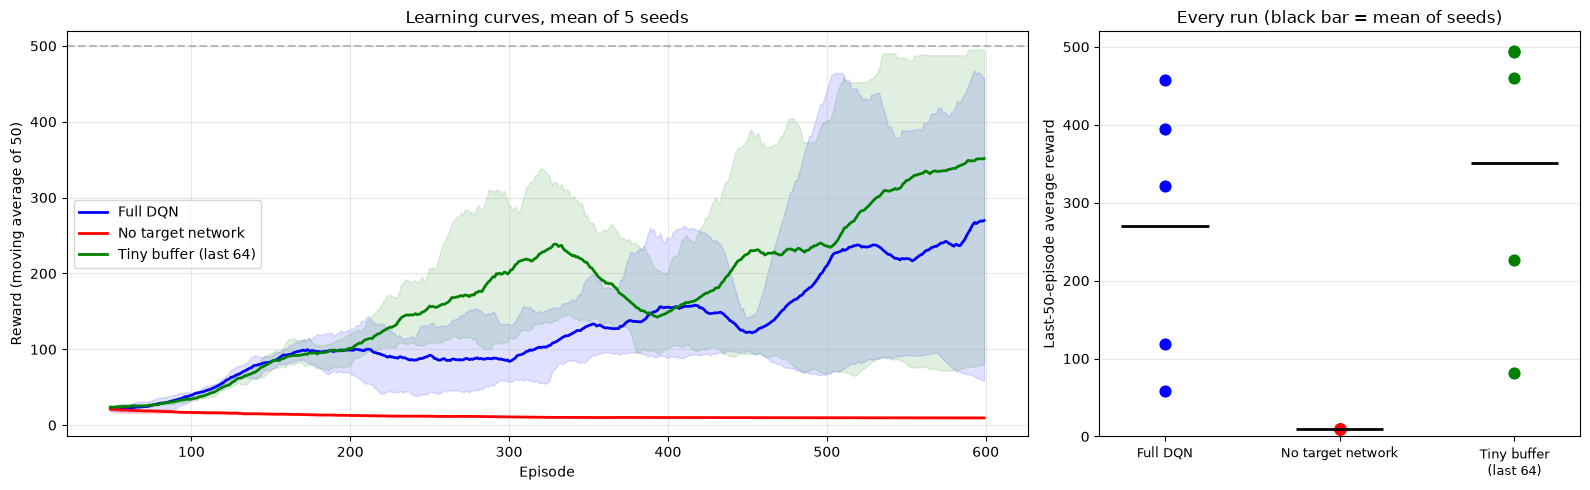

version                   mean of seeds  worst seed  best seed
Full DQN                          269.9        58.7      457.5
No target network                   9.6         9.4        9.7
Tiny buffer (last 64)             351.6        82.0      495.0


In [16]:
colors = {'Full DQN': 'blue', 'No target network': 'red', 'Tiny buffer (last 64)': 'green'}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [2, 1]})

for name, runs in ablation.items():
    smooth = np.array([np.convolve(r, np.ones(window) / window, mode='valid') for r in runs])
    x = np.arange(window - 1, num_episodes)
    ax1.plot(x, smooth.mean(0), color=colors[name], linewidth=2, label=name)
    ax1.fill_between(x, smooth.min(0), smooth.max(0), color=colors[name], alpha=0.12)
ax1.axhline(y=500, color='gray', linestyle='--', alpha=0.5)
ax1.set_xlabel('Episode')
ax1.set_ylabel('Reward (moving average of 50)')
ax1.set_title(f'Learning curves, mean of {len(SEEDS)} seeds')
ax1.legend()
ax1.grid(True, alpha=0.3)

for k, (name, runs) in enumerate(ablation.items()):
    finals = [np.mean(r[-50:]) for r in runs]
    ax2.scatter([k] * len(finals), finals, color=colors[name], s=60, zorder=3)
    ax2.hlines(np.mean(finals), k - 0.25, k + 0.25, color='black', linewidth=2, zorder=4)
ax2.set_xticks(range(len(ablation)), [n.replace(' (', '\n(') for n in ablation], fontsize=9)
ax2.set_ylabel('Last-50-episode average reward')
ax2.set_title('Every run (black bar = mean of seeds)')
ax2.set_ylim(0, 520)
ax2.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print(f'{"version":24s}{"mean of seeds":>15s}{"worst seed":>12s}{"best seed":>11s}')
for name, runs in ablation.items():
    finals = [np.mean(r[-50:]) for r in runs]
    print(f'{name:24s}{np.mean(finals):15.1f}{min(finals):12.1f}{max(finals):11.1f}')

## 17. Summary

### What we built

- A **Q-Network** (MLP) that estimates Q(s, a) for both actions from the 4-number CartPole state
- An **experience replay buffer** that stores transitions and samples random minibatches to break the link between back-to-back samples
- A **target network**, a frozen copy of the Q-network updated every 250 steps for stable targets (from the 2015 Nature version)
- **ε-greedy exploration** that decays from 1.0 toward a 0.01 floor (it reaches about 0.049 after 600 episodes)
- The **DQN training loop** (Algorithm 1 of the paper, plus the Nature target network) with a Huber loss
- A small **ablation** that removes the target network or the replay buffer and trains five seeds of each

### Paper vs this notebook

| Component | 2013 paper (Atari) | This notebook (CartPole) |
|-----------|--------------------|--------------------------|
| Q-network | CNN (2 conv + 1 FC hidden layer) | MLP (2 hidden layers) |
| Input | 84×84×4 pixels | 4-number state vector |
| Replay memory | 1,000,000 frames | 10,000 transitions |
| Target network | None (targets use the previous iteration's weights); every 10,000 steps in Nature 2015 | Copied every 250 steps |
| Loss | Squared error (Nature 2015 clips the error) | Huber (SmoothL1) |
| Actions | 4–18 per game | 2 (left/right) |

### Paper fidelity

- ✅ Experience replay with random minibatch sampling
- ✅ ε-greedy exploration with decay
- ✅ Q-learning target r + γ max Q(s', a')
- ⚠️ Target network and Huber-style loss come from the 2015 Nature version, not the 2013 paper
- ⚠️ Gradient norm clipping is our addition for stability
- ⚠️ MLP instead of CNN (fits the low-dimensional state)
- ⚠️ Smaller buffer and much more frequent target updates (fits the CartPole scale)

### What the run above shows

- **Main run (seed 42):** the 50-episode average rises from 18.4 (episode 50) to 164.6 at episode 600. It learned, but slowly and noisily.
- **Greedy evaluation:** over 20 episodes with ε=0 the final weights average 197.3 ± 7.2 (min 186, max 216), 41.5% of the 475 "solved" threshold. None of the 20 episodes reached 500. The main run did not solve CartPole-v1.
- **Demo episode:** 206 steps. The pole never tilted past 7.8°, but the cart drifted to about −2.39, at the edge of the track.
- **Predicted value vs actual return:** the network predicts about 100 (the value of surviving forever) at every step of a 207-step episode that ends in failure. It does not see the end coming.
- **Ablation, no target network:** all 5 seeds stay at about 9.6 reward for all 600 episodes (worst 9.4, best 9.7). That is even lower than the 18.4 the main run averaged at episode 50, while it was still acting mostly at random, so this agent never learns. The target network is what makes DQN train at all here.
- **Ablation, full DQN:** the five seeds finish between 58.7 and 457.5 (mean 269.9). Same code, different seed, a very different result. One seed is a weak basis for judging a DQN run.
- **Ablation, tiny buffer:** keeping only the last 64 transitions did **not** hurt on CartPole. The mean was 351.6 (range 82.0 to 495.0) against 269.9 for full DQN, but with five seeds and this spread the difference is within noise. CartPole is simple enough that correlated minibatches are tolerable. The paper's replay buffer matters more on Atari, which this notebook does not test.

So on this task the target network is clearly essential, the benefit of replay is not visible, and the run-to-run variance is large.

### Influence

This paper launched the field of deep reinforcement learning. Its core ideas, experience replay and (with the 2015 follow-up) target networks, are still standard in value-based RL. Direct descendants include Double DQN, Dueling DQN, Prioritized Replay, Rainbow, and the DeepMind line of AlphaGo, AlphaZero, and MuZero.